# 데이터 형식:
- JSON 파일 형태로 제공되며, 3종류(신문 기사, 사설, 법률)의 문서가 포함되어 있습니다.

- 데이터 구성:
- 각 문서 타입은 train/test 쌍으로 구성되어 있으며, 전체 데이터를 모두 사용하거나 원하는 문서 종류를 선택하여 학습시키면 됩니다.
## 뉴스는 너무많고 법률은 너무 적고 사설로 진행함


# 라이브러리

In [1]:
import os, json, torch, wandb
import matplotlib.pyplot as plt
import pandas as pd
from transformers import pipeline
from datasets import load_dataset, Dataset, DatasetDict
from transformers import BartTokenizer, BartTokenizerFast, DataCollatorForSeq2Seq
from transformers import BartForConditionalGeneration, TrainingArguments, Trainer
from transformers import T5TokenizerFast, T5ForConditionalGeneration, Seq2SeqTrainingArguments, Seq2SeqTrainer


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:

def load_json_dataset(file_path):
    # 하나의 JSON 파일을 열어 문서별로 text, summary 정보를 추출
    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    examples = []
    for doc in data["documents"]: # 기사 하나를 돌면서
        sentences = []
        # "text"는 중첩 리스트 형태이므로 내부의 모든 sentence를 추출
        for sublist in doc["text"]: # 하나의 텍스트에 여러 문단(sublist)
            for item in sublist: # 한 문단(sublist)의 각 문장
                sentences.append(item.get("sentence", "")) # 각 문장 append
        full_text = " ".join(sentences) # list -> str로 변환
        # abstractive 요약은 첫번째 항목 사용 (없으면 빈 문자열)
        summary = doc["abstractive"][0] if doc["abstractive"] else ""
        examples.append({
            "text": full_text, # 텍스트에 총 문장(str)
            "summary": summary, # 써머리에 기사별 요약 다 합침
        })
    return examples # 모든 기사를 돌면서 모든 문장, 모든 요약

# 기본 경로 설정
base_path = "/content/drive/MyDrive/summarization"


train_file = "train_original_editorial.json"
valid_file = "valid_original_editorial.json"


train_examples = load_json_dataset(os.path.join(base_path, train_file))
valid_examples = load_json_dataset(os.path.join(base_path, valid_file))

print("Train examples:", len(train_examples))
print("Validation examples:", len(valid_examples))

Train examples: 56760
Validation examples: 7008


In [4]:
print(train_examples[0]["text"]) # 0번재 기사의 모든 문장
print(train_examples[0]["summary"]) # 0번째 기사의 요약

이명박 대통령이 어제 30대 그룹 총수를 모아놓고 "시대적 요구는 역시 총수가 앞장서야 한다. 이미 상당한 변화의 조짐이 있다는 것을 고맙게 생각한다. 총수들께서 직접 관심을 가져주시면 빨리 전파돼 긍정적인 평가를 받을 수 있다고 본다"고 말했다. 언뜻 보아 무슨 말인지 불분명하나 이 대통령이 지난 8ㆍ15 연설 후 정몽준 의원, 정몽구 현대차 회장이 각각 2000억원과 5000억원을 기부한 사실과 '공생발전'이란 화두를 연결하면 금방 짐작이 간다. 다른 그룹 총수들도 좀 나서라고 은근히 떠민 것이다. 이 대통령은 기부에 대한 후속 선언이 나오지 않은 탓인지 총수들의 사회공헌 방안에 불만을 표시했다는 후문이다. 최근 미국 프랑스 벨기에 등에서 부유세가 거론되고 독일조차 2년간 한시적으로 5%의 자산세를 거둬 약 155조원을 마련하자는 논의가 있었다. 이런 흐름에 한국만 동떨어져 있기는 어려운 게 글로벌 시대의 특징이다. 항간에는 이번 회동 후 삼성을 비롯해 몇몇 그룹이 노블레스 오블리주 방안을 준비하고 있다는 말이 나도는데 대통령의 강요나 포퓰리즘에 의한 압박보다 자발적 문화로 만들어가야 효과가 큰 법이다. 그런 면에서 재계에 적절한 방안 마련을 맡기고 정치권이나 여론은 너무 압박하지 말고 시간을 줘야 한다. 국가채무 문제로 글로벌 경기 침체 우려가 큰 상황에서 기업들은 '생존'에 큰 부담을 느끼고 있기 때문이다. 이날 전경련에 따르면 30대 그룹은 올해 고용 12만4000명, 투자 114조원 등 '선물'을 준비했다. 세계적인 더블딥이 우려되는 상황에서 공격경영이 어렵겠지만 연초 한 번 발표한 내용을 약간 수정해 내놓은 전경련의 행태는 답답하다. 설립 50주년이 됐으면 좀 더 창의적이고 유연하게 바뀔 때도 됐다. 허창수 전경련 회장은 "대기업ㆍ중소기업이 서로 공생하고 발전할 수 있도록 노력하겠다. 기업이 사회적 책임을 다하겠다"는 원론적인 발언에 그쳐 전경련 특유의 무미건조함을 드러냈다. 한편 이건희 삼성전자 회장은 "중소기업계 협력을 강화해 국제적으로 경쟁력

In [5]:
# train exampels = [ {"text":..., "summary":...}, {"text":..., "summary":...} ]
# train_examples와 valid_examples로 Dataset 객체 생성
# Memory mapping
train_dataset = Dataset.from_list(train_examples)

# Dataset({
#     features: ['text', 'summary'],
#     num_rows: 56760
# })

valid_dataset = Dataset.from_list(valid_examples)

# DatasetDict 형태로 통합 (훈련/검증)
dataset = DatasetDict({
    "train": train_dataset,
    "validation": valid_dataset
})


# train exampels = [ {"text":..., "summary":...}, {"text":..., "summary":...} ]


# train_examples와 valid_examples로 Dataset 객체 생성
# Memory mapping
train_dataset = Dataset.from_list(train_examples)
valid_dataset = Dataset.from_list(valid_examples)

# Dataset({
#     features: ['text', 'summary'],
#     num_rows: 56760
# })


# DatasetDict 형태로 통합 (훈련/검증)
dataset = DatasetDict({
    "train": train_dataset,
    "validation": valid_dataset
})

# DatasetDict({
#     train: Dataset({
#         features: ['text', 'summary'],
#         num_rows: 56760
#     })
#     validation: Dataset({
#         features: ['text', 'summary'],
#         num_rows: 7008
#     })
# })

In [6]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'summary'],
        num_rows: 56760
    })
    validation: Dataset({
        features: ['text', 'summary'],
        num_rows: 7008
    })
})


In [7]:
# 길이가 0보다 큰 데이터만 남기기 (빈 문자열 제거)
# text와 summary 둘 다 내용이 있어야 함
dataset = dataset.filter(lambda x: len(x["text"]) > 0 and len(x["summary"]) > 0)

Filter:   0%|          | 0/56760 [00:00<?, ? examples/s]

Filter:   0%|          | 0/7008 [00:00<?, ? examples/s]

# 토큰 길이 확인

In [8]:
df_train = dataset["train"].to_pandas()
df_valid = dataset["validation"].to_pandas()
df_train.head()

,text,summary
0,"이명박 대통령이 어제 30대 그룹 총수를 모아놓고 ""시대적 요구는 역시 총수가 앞장...",이명박 대통령은 어제 30대 그룹 총수를 모아놓고 시대적 요구는 역시 총수가 앞장서...
1,이명박 정부의 첫 대통령실장을 지낸 류우익 주중대사가 통일부 장관에 내정되면서 대북...,류우억 주중대사가 통일부 장관에 내정되면서 대북정책에 대하여 일관성 있게 지켜야...
2,한국은행법 개정안이 우여곡절 끝에 국회 본회의를 통과했다. 이 법안은 글로벌 금융위...,한국은행은 금융 위기 이후 금융 시스템 안정을 위해 권한이 더욱 부여된 개정안을 통...
3,"이명박 대통령이 어제 30대 그룹 총수를 모아놓고 ""시대적 요구는 역시 총수가 앞장...",30대 그룹 총수들을 모아 회동을 가진 이명박 대통령은 간접적으로 기부에 대해 언급...
4,한나라당과 정부가 비정규직 대책을 이르면 다음주 중 내놓을 예정이다. 비정규직 임금...,내년 총선ㆍ대선을 앞두고 한나라당의 비정규직을 대상으로 한 포퓰리즘 대책들은 정치권...


# 토큰화 모델 설정

In [ ]:
model_name = "gogamza/kobart-base-v1"
tokenizer = BartTokenizerFast.from_pretrained(model_name)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.
The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'PreTrainedTokenizerFast'. 
The class this function is called from is 'BartTokenizerFast'.


count    56756.000000
mean       485.183769
std        106.422591
min         50.000000
25%        415.000000
50%        466.000000
75%        540.000000
max        969.000000
dtype: float64 

count    56756.000000
mean        49.850324
std         14.162452
min          9.000000
25%         40.000000
50%         49.000000
75%         58.000000
max        193.000000
dtype: float64 

count    7007.000000
mean      445.772513
std        69.012325
min        91.000000
25%       410.000000
50%       444.000000
75%       480.000000
max       753.000000
dtype: float64 

count    7007.000000
mean       50.831169
std        13.651254
min        13.000000
25%        41.000000
50%        50.000000
75%        59.000000
max       160.000000
dtype: float64 



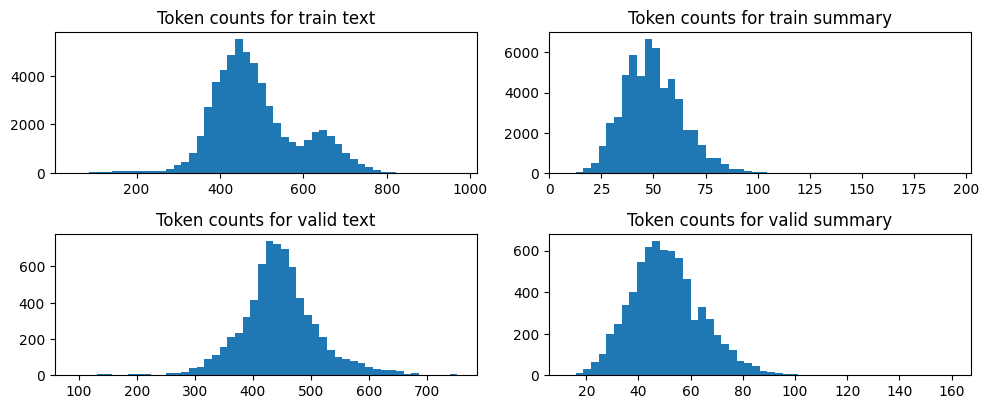

In [ ]:
# train token수 확인
token_counts_train_text = [len(tokenizer.encode(text)) for text in df_train['text']]
print(pd.Series(token_counts_train_text).describe(), "\n")
token_counts_train_summary = [len(tokenizer.encode(text)) for text in df_train['summary']]
print(pd.Series(token_counts_train_summary).describe(), "\n")

# valid token수 확인
token_counts_valid_text = [len(tokenizer.encode(text)) for text in df_valid['text']]
print(pd.Series(token_counts_valid_text).describe(), "\n")
token_counts_valid_summary = [len(tokenizer.encode(text)) for text in df_valid['summary']]
print(pd.Series(token_counts_valid_summary).describe(), "\n")

plt.figure(figsize=(10, 8))

plt.subplot(4,2,1)
plt.hist(token_counts_train_text, bins=50)
plt.title('Token counts for train text')

plt.subplot(4,2,2)
plt.hist(token_counts_train_summary, bins=50)
plt.title('Token counts for train summary')

plt.subplot(4,2,3)
plt.hist(token_counts_valid_text, bins=50)
plt.title('Token counts for valid text')

plt.subplot(4,2,4)
plt.hist(token_counts_valid_summary, bins=50)
plt.title('Token counts for valid summary')

plt.tight_layout()
plt.show()

## 토큰 시각화 결과, unk 비율도 봐야하나
### train_text : 평균이 좀 더 큼, std 106 -> outlier 조금, 살짝 right skewed
##### 2시그마가 697,
##### 3시그마가 803, 맥스가 969 -> max_len: 800으로

```text
mean       485.183769
std        106.422591
min         50.000000
25%        415.000000
50%        466.000000
75%        540.000000
max        969.000000
```

### train_summary: 평균 = 중앙값, 25%가 40, 75%가 58 -> 나름 정규분포처럼 생김, max가 193 + min = 0 존재 삭제하기
##### 2시그마: 21 ~ 78
##### 3시그마: 7 ~ 92 -> max_len: 93
```text
mean        49.850324
std         14.162452
min          9.000000
25%         40.000000
50%         49.000000
75%         58.000000
max        193.000000
```
===============================================================================================

### valid_text : 평균 = 중앙값, 25%가 410, 75%가 480 -> 나름 정규분포처럼 생김,
##### 2시그마: 307 ~ 583
##### 3시그마: 238 ~ 652 -> max_len: 652
```text
mean      445.772513
std        69.012325
min        91.000000
25%       410.000000
50%       444.000000
75%       480.000000
max       753.000000
```

### valid_summary: 평균 = 중앙, min = 0 있음 -> 삭제하기
##### 2시그마: 35 ~ 85
##### 3시그마: 28 ~ 92 -> max_len: 93
```text
mean       50.831169
std        13.651254
min        13.000000
25%        41.000000
50%        50.000000
75%        59.000000
max       160.000000
```

In [ ]:
# input_ids(원문->숫자), mask, labels(요약문->숫자) 만들어냄

''' model_inputs =
{
    # 원문 텍스트를 숫자로 바꾼 것들 (여러 문장)
    "input_ids": [
        [234, 512, 10, ...],   # 첫 번째 문장의 토큰 ID들
        [99, 1024, 55, ...],   # 두 번째 문장의 토큰 ID들
        ...
    ],

    #(1은 데이터, 0은 패딩)
    "attention_mask": [
        [1, 1, 1, ...],        # 첫 번째 문장의 마스크
        [1, 1, 1, ...],        # 두 번째 문장의 마스크
        ...
    ],
}'''

def tokenize_function(example):
    model_inputs = tokenizer(
        example["text"],
        max_length=800,
        truncation=True
    )
    labels = tokenizer(
        text_target=example["summary"],
        max_length=93,
        truncation=True
    )
    # 요약문을 숫자로 바꾼 것들 (함수 끝에서 추가됨)
    # "labels": [
    #     [51, 22, 90, ...],     # 첫 번째 요약문의 토큰 ID들
    #     [11, 33, 44, ...],     # 두 번째 요약문의 토큰 ID들
    #     ...
    # ]
    # 레이블의 토큰화된 단어 -> 숫자 (input_ids)
    # 이 숫자가 원문의 정답으로 가야함.
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_datasets = dataset.map(tokenize_function, batched=True) # 옆으로 column 이어붙이기
data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer)

Map:   0%|          | 0/56756 [00:00<?, ? examples/s]

Map:   0%|          | 0/7007 [00:00<?, ? examples/s]

In [ ]:
# model = BartForConditionalGeneration.from_pretrained(model_name)
# print(model.config.max_position_embeddings)
# # 출력 결과: 1026 (보통 1024 + 2(특수토큰용) = 1026으로 설정됨)
# 내가 지정 안 하면 최대 길이 1026을 인풋으로 받음

In [ ]:
print(tokenized_datasets)

DatasetDict({
    train: Dataset({
        features: ['text', 'summary', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 56756
    })
    validation: Dataset({
        features: ['text', 'summary', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 7007
    })
})


# Wandb 설정/

In [10]:
# Start a new wandb run to track this script.
wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="yoonwogud-lab",
    # Set the wandb project where this run will be logged.
    project="news-summary",
    sync_tensorboard=True,
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 0.00002,
        "architecture": "pko-t5",
        "dataset": "summarization",
        "epochs": 2,
        "optim": "AdamW",
        "Wdecay": "0.01"
    },
)

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: yoonwogud (yoonwogud-lab) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


# bart 학습 시작

In [ ]:
model = BartForConditionalGeneration.from_pretrained(model_name)
training_args = TrainingArguments(
    output_dir="test-trainer",
    report_to="wandb",

    num_train_epochs=2,              # 에폭 수 (기본값: 3.0)
    per_device_train_batch_size=16,  # 학습 시 배치 크기 (기본값: 8)
    per_device_eval_batch_size=16,   # 검증 시 배치 크기 (기본값: 8)

    # 자주 쓰는 추가 설정들
    learning_rate=0.00002,              # 학습률 (기본값: 5e-5)
    weight_decay=0.01,               # 가중치 감쇠 (과적합 방지)
    save_total_limit=2,              # 모델 저장 개수 제한 (용량 절약)
    eval_strategy="epoch",     # 매 에폭마다 검증(Evaluation) 수행
    save_strategy="epoch",           # 매 에폭마다 모델 저장
    load_best_model_at_end=True,     # 학습 끝나면 가장 성능 좋았던 모델로 되돌리기
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    tokenizer=tokenizer,
)

trainer.train()
wandb.finish()

You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.


model.safetensors:   0%|          | 0.00/495M [00:00<?, ?B/s]

/tmp/ipython-input-2551318716.py:23: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss
1,2.079900,1.883155
2,1.925300,1.858523


/usr/local/lib/python3.12/dist-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'forced_eos_token_id': 1}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(
There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


eval/loss,█▁
eval/runtime,▁█
eval/samples_per_second,█▁
eval/steps_per_second,█▁
train/epoch,▁▂▂▃▃▄▄▄▅▅▆▆▇▇███
train/global_step,▁▂▂▃▃▄▄▄▅▅▆▆▇▇███
train/grad_norm,█▅▆▃▁▂▃▂▅▃▂▃▂▁
train/learning_rate,█▇▇▆▆▅▅▄▄▃▃▂▂▁
train/loss,█▅▄▄▃▃▃▂▁▁▁▁▁▁
eval/loss,1.85852
eval/runtime,84.8041


# bart 요약 결과
- 얜 깜빡하고 모델 저장 안해서 Rouge못 구했습니다. ㅜ

In [ ]:
summarizer = pipeline("summarization", model=model, tokenizer=tokenizer)

for i in range(10):
    sample_text = tokenized_datasets["validation"][i]["text"]
    prompt = f"원문:\n{sample_text}\n요약:"
    print(f"예시 {i+1}:")
    print(prompt)

    result = summarizer(prompt, max_length=130, min_length=30, do_sample=False) # 1위만 사용
    print(result[0]['summary_text'])
    print("-" * 50)

Device set to use cuda:0
Both `max_new_tokens` (=256) and `max_length`(=130) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


예시 1:
원문:
더불어민주당 이해찬 대표가 30 일 오후 국회에서 기자간담회를 열고 조국 전 법무부 장관 사태와 관련해 "국민 여러분께 매우 송구하다"고 밝혔다. 더불어민주당 이해찬 대표가 30 일 기자간담회를 열고 '조국 사태'와 관련, "국민 여러분께 매우 송구하다"는 입장을 밝혔다. 이 대표는 "검찰 개혁이란 대의에 집중하다 보니, 국민 특히 청년이 느꼈을 불공정에 대한 상대적 박탈감, 좌절감을 깊이 있게 헤아리지 못했다"며 "여당 대표로서 무거운 책임감을 느낀다"고 머리를 숙였다. 조국 전 법무부 장관이 14 일 사퇴한 이후 이 대표가 당 안팎의 쇄신 요구에 대해 입장을 표명한 것은 이번이 처음이다. 청와대와 여당은 '조국 정국'을 거치며 분출된 '공정'과 '정의'의 민심을 받들어 검찰 개혁에 매진하겠다면서도 두 달간 극심한 분열과 갈등을 초래한데 대해선 진지하게 성찰하는 모습을 보이지 않았다. 그나마 초선인 이철희 의원이 "당이 대통령 뒤에 비겁하게 숨어 있었다"고 비판했고, 표창원 의원은 "책임을 느끼는 분들이 각자 형태로 그 책임감을 행동으로 옮겨야 할 때"라고 지적했다. 뒤늦게나마 이 대표가 자성의 목소리를 내긴 했으나 당 안팎의 쇄신 요구에 어떻게 응할지 구체적 플랜을 제시하지 못해 여전히 안이하다는 지적도 나온다. 이 대표는 28 일 윤호중 사무총장을 단장으로 하는 총선기획단을 발족했고 조만간 인재영입위원회도 출범시킬 계획이라고 밝혔다. 이 대표는 "민주당의 가치를 공유하는 참신한 인물을 영입해 준비된 정책과 인물로 승부하겠다"고 다짐했다. 하지만 당 일각에선 "총선기획단장을 비롯한 당직 인선부터 쇄신 의지를 보여야 한다"는 비판의 목소리가 나온다. 무조건 물러나는 게 능사는 아니지만 국정 혼선을 초래한 데 대해 당 지도부가 겸허하게 책임지는 모습을 보이는 게 쇄신의 출발점이 돼야 한다는 지적도 있다. 선거는 대중의 이해와 요구를 잘 대표하는 정치인을 뽑는 행위다. 민생을 외면하며 낡은 이념과 진영 싸움에 매몰된 구시대 인물들을 과감히 물갈

Both `max_new_tokens` (=256) and `max_length`(=130) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


더불어민주당 이해찬 대표가 30일 기자간담회를 열고 조국 전 법무부 장관 사태와 관련해 "국민 여러분께 매우 송구하다"는 입장을 밝혔지만 당 일각에선 "총선기획단장을 비롯한 당직 인선부터 쇄신 의지를 보여야 한다"는 비판의 목소리가 나오며 무조건 물러나는 게 능사는 아니지만 국정 혼선을 초래한 데 대해 당 지도부가 겸허하게 책임지는 모습을 보이는 게 쇄신의 출발점이 돼야 한다는 지적도 나오고 있다.    민생을 외면하며 낡은 이념과 진영 싸움에 매몰된 구시대 인물들을 과감히 물갈이하라는 게 국민의 요구이며 민생을 외면하며 낡은 이념과 진영 싸움에 매몰된 구시대 인물들을 과감히 물갈이하라는 게 국민의 요구이다.      민생을 외면하며 낡은 이념과 진영 싸움에 매몰된 구시대 인물들을 과감히 물갈이하라는 게 국민의 요구이다.     민생을 외면하며 낡은 이념과 진영 싸움에 매몰된 구시대 인물들을 과감히 물갈이하라는 게 국민의 요구이다.                                                  
--------------------------------------------------
예시 2:
원문:
탈원전 정책에서 비롯된 한국전력의 경영 부담이 결국 전기료 인상을 초래하게 됐다. 김종갑 한전 사장은 언론 인터뷰에서 "정부 정책에 따라 도입된 각종 전기료 특례할인을 모두 폐지하고 전기요금 원가공개 방안을 정부와 협의하겠다"고 밝혔다. 특례할인은 여름철 누진제, 주택용 절전 및 전기차 충전 등의 명목으로 전기료를 깎아주는 제도로서, 작년 1 조 1434 억원에 달했다. 이 제도가 없어지면 부담은 고스란히 국민에게 돌아가게 된다. 전기료 인상은 예견됐던 것이나 마찬가지다. 문재인 정부 출범 이후 탈원전 정책이 가속화되면서 한전 경영이 악화일로를 달려왔기 때문이다. 원전 가동을 줄이고 발전 단가가 높은 민간 발전사의 전기 구매를 늘린 탓에 한전의 발전 원가는 2016 년 25 조원 수준에서 2018 년 38 조원 수준으로 급등했다. 영업이

Both `max_new_tokens` (=256) and `max_length`(=130) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


문재인 정부 출범 이후 탈원전 정책이 가속화되면서 한국전력의 경영이 악화일로를 달려왔기 때문에 한전의 앞날과 더 늘어날 국민 부담을 고민한다면 정부는 이제라도 탈원전 속도를 조절하면서 무엇이 옳은지 냉정히 따져야 한다.  정부는 이제라도 탈원전 속도를 조절하면서 무엇이 옳은지 냉정히 따져야 한다.     한전을 빈껍데기로 만들고 전기료 인상을 잠시 미룬다 해도 그 부담은 결국 국민 몫으로 한꺼번에 돌아올 것임을 명심해야 한다.                                   한전의 앞날과 더 늘어날 국민 부담을 고민한다면 정부는 이제라도 탈원전 속도를 조절하면서 무엇이 옳은지 냉정하게 따져야 한다.            한전의 앞날과 더 늘어날 국민 부담을 고민한다면 정부는 이제라도 탈원전 속도를 조절하면서 무엇이 옳은지 냉정히 따져야 한다.         한전을 빈껍데기로 만들고 전기료 인상을 잠시 미룬다 해도 그 부담은 고스란히 국민 몫으로 돌아올 것임을 명심해야 한다.            
--------------------------------------------------
예시 3:
원문:
북한이 그제 금강산국제관광국 명의로 통일부와 현대아산에 통지문을 보내 금강산관광 시설 철거와 관련해 기존 '문서 교환' 방식의 협의를 거듭 주장했다. 전날 우리 정부의 '대면 실무회담' 제안을 단 하루 만에 거절한 것이다. 어떤 형태로든 남북 당국자 간 직접 대화를 하지 않겠다는 의도다. 단절된 남북대화 재개의 기회를 걷어차는 어리석은 몽니가 아닐 수 없다. 남북관계를 훼손하는 북한의 안하무인 억지 처사는 어제오늘 일이 아니다. 애초 금강패밀리비치호텔, 해금강호텔 등 수천억원이 투자된 민간기업 재산권이 걸려 있는 금강산 내 남측 시설을 "싹 들어내라"는 것부터가 상식 밖이다. 더구나 현대아산의 금강산관광지구 독점사업권은 유효기간이 50 년이므로, 아직 30 년 가까이 남아 있는 상황이다. 일방적으로 '철거 운운'한 것은 사실상 공갈·협박이나 다름없다.

... (10 outputs left out)

Both `max_new_tokens` (=256) and `max_length`(=130) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


불법체류를 막기 위해 이주노동자가 출국한 뒤 퇴직금을 받도록 한 '출국만기보험 제도'가 퇴직금 미지급자를 양산하고 있는 가운데 이주노동자 관련 단체에서는 정부가 법을 개정한 취지가 불법체류자를 줄이기 위한 것이었으나 불법체류자 감소에 큰 효과를 내지 못하는 만큼 출국 후 퇴직금 수령제도를 철폐해야 한다고 주장하고 있으며 이주노동자에게만 그 시점을 '출국'으로 다르게 적용하는 것은 기본권 침해라는 지적도 나오고 있다.     소멸시효 3 년이 지날 때까지 이주노동자가 찾아가지 않은 미지급금이 많다보니 한국산업인력공단에서는 '휴면보험금 찾아주기' 사업을 펼치고 있으나 미지급금 찾아주기 사업까지 진행하는 데서 행정 낭비가 발생하고 있다.     소멸시효 3 년이 지날 때까지 이주노동자가 찾아가지 않은 미지급금이 많다보니 한국산업인력공단에서는 '휴면보험금 찾아주기' 사업을 펼치고 있다.     이주노동자 관련 단체에서는 정부가 법을 개정한 취지가 불법체류자 감소에 큰 효과를 내지 못하는 만큼 출국 후 퇴직금 수령제도를 철폐해야 한다고 주장하고 있다.     이주노동자에게만 그 시점을 '출국'으로 다르게 적용하는 것은 기본권 침해라는 지적도
--------------------------------------------------
예시 9:
원문:
법무부가 제정한 훈령 '형사사건 공개 금지 등에 관한 규정'을 둘러싼 논란이 뜨겁다. 당장 국민의 알권리와 정면 충돌하고 있다는 지적이 비등하고 있다. 법무부의 훈령은 사건 관계인의 인권보호를 위해 검찰의 수사 상황을 전면 비공개하고, 오보 언론에 대한 처벌 수단을 마련하겠다는 게 그 요지다. 구체적으로는 검사와 수사관 등 관계자가 기자와 개별적으로 만날 수 없도록 했다. 또 검찰수사와 관련해 오보를 내면 해당 언론사는 브리핑은 물론 검찰청 출입 자체가 제한된다. 다만 공보 담당자와는 만날 수 있다. 한마디로 기자는 알려주는 내용만 받아쓰라는 것이다. 언론 자유의 침해가 심각하게 우려되는 조치가 아닐 수 없다. 이 규정을 만

Both `max_new_tokens` (=256) and `max_length`(=130) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


법무부가 법무부가 제정한 '형사사건 공개 금지 등에 관한 규정'을 둘러싼 논란이 뜨겁고 이는 피의사실 공개로 피의자 인권이 침해당하는 폐해를 막기 위한 조치라는 게 법무부 설명이지만 그 제한이 과도하다는 게 문제이며 정부가 규정 시행을 밀어붙인다면 비판 언론에 재잘을 물리려는 의도로 볼 수 밖에 없다.      국가가 언론을 통제하고 통제를 하는 시절에도 없었던 일이다.    군사정권 시절에도 없었던 일이다.     군사정권 시절에도 없었던 일이다.     군사정권 시절에도 없었던 일이다.     군사정권 시절에도 없었던 일이다.         언론의 감시 기능이 무력화되면 과거 적폐가 되살아날 수도 있다.                 그 제한이 과도하다는 게 문제이다.                                                                         
--------------------------------------------------
예시 10:
원문:
딱 한달이다. 두달도 이어가지 못했다. 5 개월만에 생산·소비·투자 등 경제 활동 3 대 지표가 모두 상승하며 희망을 줬던 산업활동동향(8 월)이 다시 한숨 속 위기감으로 빠져드는데는 한달이면 충분했다. 통계청이 31 일 발표한 '9 월 산업활동 동향'에서 지난달 전(全)산업 생산지수(계절조정계열)는 108.0 으로, 전월보다 0.4% 감소했다. 광공업 생산은 증가했지만, 도소매와 금융·보험업을 중심으로 서비스업 생산이 줄어든 것이 영향을 미쳤다. 소매판매는 음식료품과 의복 판매가 감소하면서 전월보다 2.2%줄어들었다. 감소폭은 2017 년 12 월(-2.4%) 이후 가장 컸다. 이제는 익숙해져 그러려니 하지만 통계청의 설명은 여지없이 기저효과와 날씨 때문이란 설명으로 일관한다. 올해 추석이 이른 9 월이어서 소비가 전달인 8 월으로 분산됐고 9 월엔 잦은 태풍과 장마 등으로 야외활동이 줄어들면서 숙박·음식업과 운수·창고업, 예술·스포츠·여가업 등 서비스업

# T5 model

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/209 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.10G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.10G [00:00<?, ?B/s]

count    56756.000000
mean       806.501075
std        167.961374
min         75.000000
25%        698.000000
50%        779.000000
75%        894.000000
max       1555.000000
dtype: float64 

count    56756.000000
mean        83.486592
std         22.827442
min         13.000000
25%         67.000000
50%         82.000000
75%         98.000000
max        278.000000
dtype: float64 

count    7007.000000
mean      748.828029
std       113.630740
min       146.000000
25%       690.000000
50%       749.000000
75%       806.000000
max      1276.000000
dtype: float64 

count    7007.000000
mean       86.049665
std        22.272406
min        23.000000
25%        71.000000
50%        85.000000
75%       100.000000
max       243.000000
dtype: float64 



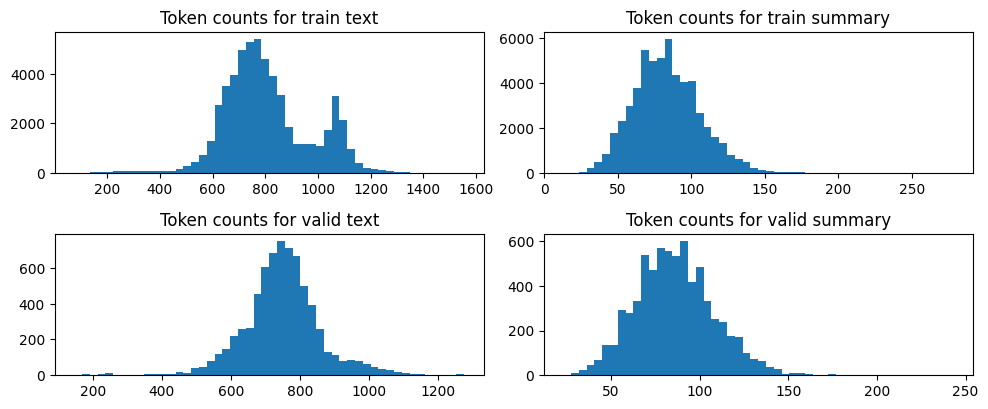

In [9]:
# pko-t5 는 한국어 전용 데이터로 학습한 T5 v1.1입니다
model_name = "paust/pko-t5-base"
tokenizer = T5TokenizerFast.from_pretrained(model_name)
model = T5ForConditionalGeneration.from_pretrained(model_name)


# train token수 확인
token_counts_train_text = [len(tokenizer.encode(text)) for text in df_train['text']]
print(pd.Series(token_counts_train_text).describe(), "\n")
token_counts_train_summary = [len(tokenizer.encode(text)) for text in df_train['summary']]
print(pd.Series(token_counts_train_summary).describe(), "\n")

# valid token수 확인
token_counts_valid_text = [len(tokenizer.encode(text)) for text in df_valid['text']]
print(pd.Series(token_counts_valid_text).describe(), "\n")
token_counts_valid_summary = [len(tokenizer.encode(text)) for text in df_valid['summary']]
print(pd.Series(token_counts_valid_summary).describe(), "\n")

plt.figure(figsize=(10, 8))

plt.subplot(4,2,1)
plt.hist(token_counts_train_text, bins=50)
plt.title('Token counts for train text')

plt.subplot(4,2,2)
plt.hist(token_counts_train_summary, bins=50)
plt.title('Token counts for train summary')

plt.subplot(4,2,3)
plt.hist(token_counts_valid_text, bins=50)
plt.title('Token counts for valid text')

plt.subplot(4,2,4)
plt.hist(token_counts_valid_summary, bins=50)
plt.title('Token counts for valid summary')

plt.tight_layout()
plt.show()

## 토큰 시각화 결과
#### train text
- 분류하는 방식이 다른가 숫자가 bart랑 꽤 차이가 남. 그래도 분포는 유사한듯
- 3시그마 1310

#### train summary
- 160으로


#### valid text
- 1089

#### valid summary
- 152


### 1280으로 하기


In [15]:
model_name = "paust/pko-t5-base"
# https://huggingface.co/paust/pko-t5-base
tokenizer = T5TokenizerFast.from_pretrained(model_name)
model = T5ForConditionalGeneration.from_pretrained(model_name)

# 2. 토크나이징 함수 (T5용 Prefix 추가 및 길이 수정)
prefix = "summarize: "

def tokenize_function_t5(examples):
    inputs = [prefix + doc for doc in examples["text"]]

    model_inputs = tokenizer(
        inputs,
        max_length=1280,
        truncation=True
    )

    labels = tokenizer(
        text_target=examples["summary"],
        max_length=160,
        truncation=True
    )

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_datasets = dataset.map(tokenize_function_t5, batched=True)

data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)


training_args = Seq2SeqTrainingArguments(
    output_dir="./pko-t5-results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8, # 배치
    per_device_eval_batch_size=8,
    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=3,
    predict_with_generate=True, # 정답 맞추기(loss)만 하지말고 generate해서 평가해라, 근데 rouge로 안하고 loss로해서 의미없음, ㅅㅂ껐어야됐네
    fp16=True, # bf, fp / 텐서코어에서 16비트 사용
    #fp (1,5,10)사인,지수,맨티사 / 지수는 적고 멘티사가 좀 더 긺, -> 표현은 적지만 세밀
    #bf (1,8,7)사인,지수,맨티사 / 지수는 더 넓고 맨티사는 더 적음 -> 표현 많고 조금 부정확. 이거 썼어야됐네 ㅅㅂ
    logging_dir='./logs',
    logging_steps=100,
    report_to="wandb",
    load_best_model_at_end=True,

    metric_for_best_model="loss", # 로스값을 기준으로 베스트 모델 뽑기, 무난
    greater_is_better=False, # 클수록 좋은거다를 false로, 로스니깐 작아야됨

    # metric="rouge1", greater=True ㅈㄴ 느림

    generation_max_length=160, # 160보다 긴거 생성 방지
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
)

trainer.train()

save_path = "./best_pko_t5_model"
trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)


Map:   0%|          | 0/56756 [00:00<?, ? examples/s]

Map:   0%|          | 0/7007 [00:00<?, ? examples/s]

/tmp/ipython-input-2399150078.py:59: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(


Epoch,Training Loss,Validation Loss
1,1.159100,1.049831
2,1.106200,1.038789
3,1.089800,1.032177


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


('./best_pko_t5_model/tokenizer_config.json',
 './best_pko_t5_model/special_tokens_map.json',
 './best_pko_t5_model/tokenizer.json')

In [20]:
!pip install evaluate
!pip install rouge_score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.6 MB/s eta 0:00:00


# T5 결과

In [26]:
from transformers import T5ForConditionalGeneration, T5TokenizerFast
import torch
import random

save_path = "./best_pko_t5_model"
model = T5ForConditionalGeneration.from_pretrained(save_path).to("cuda")
tokenizer = T5TokenizerFast.from_pretrained(save_path)


print("=== Generating 10 Random Summaries ===\n")

for i in range(10):
    # 랜덤 인덱스 뽑기
    random_idx = random.randint(0, len(dataset['validation']) - 1)
    sample = dataset['validation'][random_idx]

    input_text = sample['text']
    target_summary = sample['summary']

    # T5 Prefix 추가 및 토크나이징
    input_text_with_prefix = "summarize: " + input_text
    inputs = tokenizer(
        input_text_with_prefix,
        return_tensors="pt",
        max_length=1280,
        truncation=True
    ).to("cuda")

    # 추론 (Generate)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_length=160,
            num_beams=3,            # 빔 서치 3
            no_repeat_ngram_size=3, # 3-gram 반복 방지
            early_stopping=True
        )

    # 디코딩
    generated_summary = tokenizer.decode(outputs[0], skip_special_tokens=True)

    # 출력
    print(f"[{i+1}/10] Sample Index: {random_idx}")
    print(f"Input (Prefix): {input_text[:100]}...") # 앞부분만 살짝
    print(f"Target Summary: {target_summary}")
    print(f"Generated     : {generated_summary}")
    print("-" * 80 + "\n")

=== Generating 10 Random Summaries ===

[1/10] Sample Index: 4566
Input (Prefix): 서울ㆍ수도권을 중심으로 건설사들의 고질적인 분양가 뻥튀기 경쟁이 재연되고 있다. 최근 청약을 받은 서울 강동구 '고덕 아이파크'는 3.3㎡당 평균 분양값이 2450만원이었는데 대형...
Target Summary: 서울ㆍ수도권을 중심으로 분양가가 주변시세보다 높게 책정되는 등 건설사들의 전형적인 분양가 뻥튀기 경쟁이 나타나고 있는데 건설사들은 오랜만에 조성된 청약 열기를 이끌려면 소비자들을 봉으로 삼는 행태부터 바로 잡아야 한다.
Generated     : 서울ᆞ수도권을 중심으로 건설사들의 고질적인 분양가 뻥튀기 경쟁이 재연되고 있는 가운데 건설사들은 모처럼 조성된 청약 열기에 찬물을 끼얹어 화를 자초하지 않으려면 소비자들을 봉으로 삼는 행태부터 고쳐야 한다.
--------------------------------------------------------------------------------

[2/10] Sample Index: 2041
Input (Prefix): 새해를 맞는 시점이 다가오고 있지만 기업들은 착잡하기만 하다. 그 어느 때보다 어려운 1 년을 보냈지만 더 나아지리라는 희망이 잘 보이지 않기 때문이다. 한국경영자총협회가 206 ...
Target Summary: 무엇보다 심각한 것은 '경제의 허리'로 불리는 제조업체들이 그 직격탄을 맞고 있다는 점으로 좀 더 기업하기 좋은 환경 조성에 신경 써 줬으면 좋겠다"는 한 부품사 사장의 호소를 정부는 더 이상 외면하지 말아야 한다.
Generated     : 한국경영자총협회가 206 개 회원사를 대상으로 2020 년 경영 전망을 조사한 결과에 따르면 47.4%가 내년에 '긴축경영'에 나서겠다고 밝혔으며 이는 정부가 '대외 여건 악화'를 경제난의 주요인으로 꼽는 것과 달리 잘못된 정책과 규제를 가장 큰 애로 요인으로 꼽고 있어 정부는 더 이상 외

# rouge 평가

In [ ]:
import torch
from transformers import T5ForConditionalGeneration, T5TokenizerFast
import evaluate
from tqdm import tqdm
import random

# 1. 모델 및 토크나이저 로드
save_path = "./best_pko_t5_model"
model = T5ForConditionalGeneration.from_pretrained(save_path).to("cuda")
tokenizer = T5TokenizerFast.from_pretrained(save_path)

# 2. ROUGE 메트릭 로드
rouge = evaluate.load('rouge')

# 3. 데이터 준비 (랜덤 700개 추출)
val_data = dataset['validation']
num_samples = 700  # 700개 설정

# 인덱스 랜덤 추출 (고정 시드 사용으로 재현성 확보)
random.seed(42)
random_indices = random.sample(range(len(val_data)), num_samples)

# 선택된 데이터만 리스트로 만들기
selected_articles = [val_data[i]['text'] for i in random_indices]
selected_targets = [val_data[i]['summary'] for i in random_indices]

# 4. 배치 단위로 추론 및 평가 함수
def evaluate_rouge_subset(model, tokenizer, articles, targets, batch_size=32):
    model.eval()

    predictions = []
    references = []

    # 배치 처리
    print(f"Generating summaries for {len(articles)} samples...")
    for i in tqdm(range(0, len(articles), batch_size)):
        batch_articles = articles[i : i + batch_size]
        batch_targets = targets[i : i + batch_size]

        # T5 Prefix 추가
        inputs = ["summarize: " + text for text in batch_articles]

        # 토크나이징
        model_inputs = tokenizer(
            inputs,
            max_length=1280,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        ).to("cuda")

        # 요약 생성
        with torch.no_grad():
            outputs = model.generate(
                input_ids=model_inputs["input_ids"],
                attention_mask=model_inputs["attention_mask"],
                max_length=160,
                num_beams=5,        # 그리디 말고 여러 갈래 찾기
# 올리려면 반복 방지, 반복 페널티, 길이 제한, 빔서치
                no_repeat_ngram_size=3,
                early_stopping=True
            )

        # 디코딩
        decoded_preds = tokenizer.batch_decode(outputs, skip_special_tokens=True)

        predictions.extend(decoded_preds)
        references.extend(batch_targets)


    print("Calculating ROUGE scores...")
    results = rouge.compute(predictions=predictions, references=references)

    return results

rouge_scores = evaluate_rouge_subset(model, tokenizer, selected_articles, selected_targets, batch_size=32)

print(f"\n=== ROUGE Scores (Sample {num_samples}) ===")
print(f"ROUGE-1: {rouge_scores['rouge1']:.4f}")
print(f"ROUGE-2: {rouge_scores['rouge2']:.4f}")
print(f"ROUGE-L: {rouge_scores['rougeL']:.4f}")
print(f"ROUGE-Lsum: {rouge_scores['rougeLsum']:.4f}")

Generating summaries for 700 samples...


100%|██████████| 22/22 [05:52<00:00, 16.03s/it]


Calculating ROUGE scores...

=== ROUGE Scores (Sample 700) ===
ROUGE-1: 0.2781
ROUGE-2: 0.1157
ROUGE-L: 0.2738
ROUGE-Lsum: 0.2746


## Rouge 700개로...

## beam = 3 쓰레기까지 ㄴ아니고 그냥 좀 안 좋은듯..
```text
=== ROUGE Scores (Sample 700) ===
ROUGE-1: 0.2829
ROUGE-2: 0.1194
ROUGE-L: 0.2782
ROUGE-Lsum: 0.2792
```


## beam = 5
- 더 내려감
``` text
=== ROUGE Scores (Sample 700) ===
ROUGE-1: 0.2781
ROUGE-2: 0.1157
ROUGE-L: 0.2738
ROUGE-Lsum: 0.2746
```